In [ ]:
install.packages("tidyverse")

Installing package into ‘/usr/local/lib/R/site-library’
(as ‘lib’ is unspecified)



In [ ]:
library(tidyverse)

── Attaching core tidyverse packages ──────────────────────── tidyverse 2.0.0 ──
✔ dplyr     1.2.1     ✔ readr     2.2.0
✔ forcats   1.0.1     ✔ stringr   1.6.0
✔ ggplot2   4.0.3     ✔ tibble    3.3.1
✔ lubridate 1.9.5     ✔ tidyr     1.3.2
✔ purrr     1.2.2     
── Conflicts ────────────────────────────────────────── tidyverse_conflicts() ──
✖ dplyr::filter() masks stats::filter()
✖ dplyr::lag()    masks stats::lag()
ℹ Use the conflicted package (<http://conflicted.r-lib.org/>) to force all conflicts to become errors


In [ ]:
students <- read_csv("https://raw.githubusercontent.com/hadley/r4ds/main/data/students.csv")

Rows: 6 Columns: 5
── Column specification ────────────────────────────────────────────────────────
Delimiter: ","
chr (4): Full Name, favourite.food, mealPlan, AGE
dbl (1): Student ID

ℹ Use `spec()` to retrieve the full column specification for this data.
ℹ Specify the column types or set `show_col_types = FALSE` to quiet this message.


In [ ]:
students <- as_tibble(students)
students

Student ID,Full Name,favourite.food,mealPlan,AGE
<dbl>,<chr>,<chr>,<chr>,<chr>
1,Sunil Huffmann,Strawberry yoghurt,Lunch only,4
2,Barclay Lynn,French fries,Lunch only,5
3,Jayendra Lyne,N/A,Breakfast and lunch,7
4,Leon Rossini,Anchovies,Lunch only,NA
5,Chidiegwu Dunkel,Pizza,Breakfast and lunch,five
6,Güvenç Attila,Ice cream,Lunch only,6


In [ ]:
print(paste("Number of rows:", nrow(students)))

[1] "Number of rows: 6"


In [ ]:
print(paste("Number of columns:", ncol(students)))

[1] "Number of columns: 5"


In [ ]:
students <- students %>% mutate(across(where(is.character), ~na_if(., "N/A")))

In [ ]:
students

Student ID,Full Name,favourite.food,mealPlan,AGE
<dbl>,<chr>,<chr>,<chr>,<chr>
1,Sunil Huffmann,Strawberry yoghurt,Lunch only,4
2,Barclay Lynn,French fries,Lunch only,5
3,Jayendra Lyne,NA,Breakfast and lunch,7
4,Leon Rossini,Anchovies,Lunch only,NA
5,Chidiegwu Dunkel,Pizza,Breakfast and lunch,five
6,Güvenç Attila,Ice cream,Lunch only,6


In [ ]:
students <- students %>% rename(StudentID = `Student ID`, FullName = `Full Name`)

In [ ]:
students

StudentID,FullName,favourite.food,mealPlan,AGE
<dbl>,<chr>,<chr>,<chr>,<chr>
1,Sunil Huffmann,Strawberry yoghurt,Lunch only,4
2,Barclay Lynn,French fries,Lunch only,5
3,Jayendra Lyne,NA,Breakfast and lunch,7
4,Leon Rossini,Anchovies,Lunch only,NA
5,Chidiegwu Dunkel,Pizza,Breakfast and lunch,five
6,Güvenç Attila,Ice cream,Lunch only,6


In [ ]:
students <- students %>% rename_with(tolower)

In [ ]:
students

studentid,fullname,favourite.food,mealplan,age
<dbl>,<chr>,<chr>,<chr>,<chr>
1,Sunil Huffmann,Strawberry yoghurt,Lunch only,4
2,Barclay Lynn,French fries,Lunch only,5
3,Jayendra Lyne,NA,Breakfast and lunch,7
4,Leon Rossini,Anchovies,Lunch only,NA
5,Chidiegwu Dunkel,Pizza,Breakfast and lunch,five
6,Güvenç Attila,Ice cream,Lunch only,6


In [ ]:
students <- students %>% mutate(age = str_replace(age, 'five', '5')) %>% mutate(age = as.numeric(age))

In [ ]:
students

studentid,fullname,favourite.food,mealplan,age
<dbl>,<chr>,<chr>,<chr>,<dbl>
1,Sunil Huffmann,Strawberry yoghurt,Lunch only,4
2,Barclay Lynn,French fries,Lunch only,5
3,Jayendra Lyne,NA,Breakfast and lunch,7
4,Leon Rossini,Anchovies,Lunch only,NA
5,Chidiegwu Dunkel,Pizza,Breakfast and lunch,5
6,Güvenç Attila,Ice cream,Lunch only,6


In [ ]:
leeftijd <- students$age

In [ ]:
leeftijd

[1]  4  5  7 NA  5  6

In [ ]:
leeftijd <- na.omit(leeftijd)

In [ ]:
leeftijd

[1] 4 5 7 5 6
attr(,"na.action")
[1] 4
attr(,"class")
[1] "omit"

In [ ]:
gemiddelde_leeftijd <- mean(leeftijd)
print(paste("De gemiddelde leeftijd is:", gemiddelde_leeftijd))

[1] "De gemiddelde leeftijd is: 5.4"


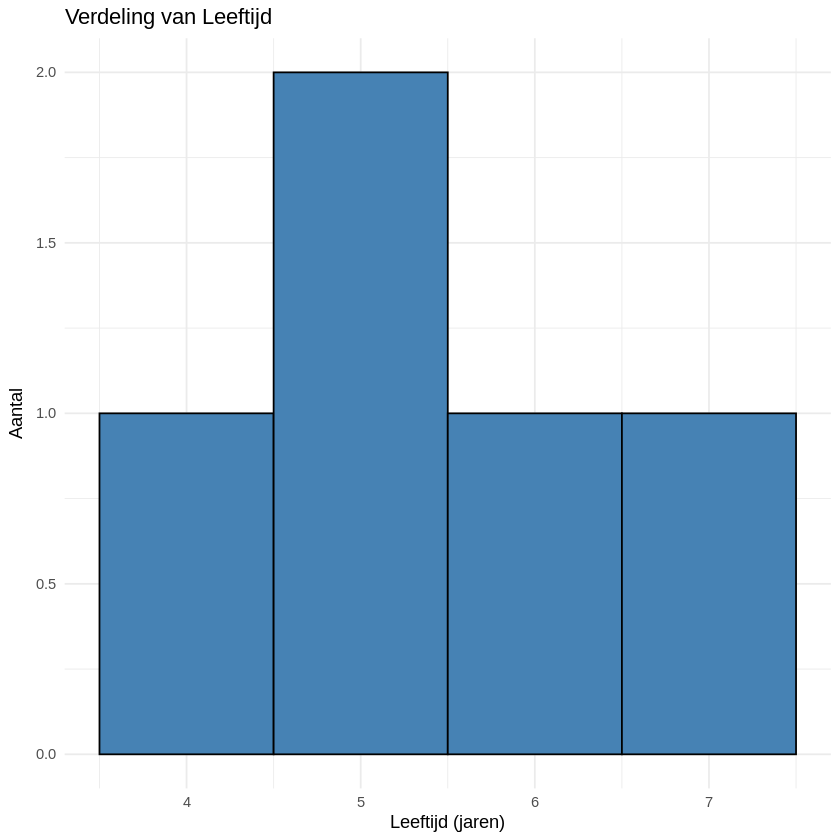

In [ ]:
hist_plot <- ggplot(data = data.frame(leeftijd = leeftijd), aes(x = leeftijd)) +
  geom_histogram(binwidth = 1, fill = "steelblue", color = "black") +
  labs(title = "Verdeling van Leeftijd",
       x = "Leeftijd (jaren)",
       y = "Aantal") +
  theme_minimal()

print(hist_plot)

In [ ]:
write.csv(leeftijd, "leeftijd.csv", row.names = FALSE)

# Excel-bestanden

In [ ]:
install.packages("readxl")

Installing package into ‘/usr/local/lib/R/site-library’
(as ‘lib’ is unspecified)



In [ ]:
library(readxl)

In [ ]:
students_excel <- read_excel("students.xlsx")
(students_excel)

Student ID,Full Name,favourite.food,mealPlan,AGE
<dbl>,<chr>,<chr>,<chr>,<chr>
1,Sunil Huffmann,Strawberry yoghurt,Lunch only,4.0
2,Barclay Lynn,French fries,Lunch only,5.0
3,Jayendra Lyne,N/A,Breakfast and lunch,7.0
4,Leon Rossini,Anchovies,Lunch only,NA
5,Chidiegwu Dunkel,Pizza,Breakfast and lunch,five
6,Güvenç Attila,Ice cream,Lunch only,6.0


In [ ]:
students_excel <- students_excel %>% mutate(across(where(is.character), ~na_if(., "N/A")))

In [ ]:
students_excel <- students_excel %>% rename(StudentID = `Student ID`, FullName = `Full Name`)

In [ ]:
students_excel <- students_excel %>% rename_with(tolower)

In [ ]:
students_excel <- students_excel %>% mutate(age = str_replace(age, 'five', '5')) %>% mutate(age = as.numeric(age))

In [ ]:
students_excel

studentid,fullname,favourite.food,mealplan,age
<dbl>,<chr>,<chr>,<chr>,<dbl>
1,Sunil Huffmann,Strawberry yoghurt,Lunch only,4
2,Barclay Lynn,French fries,Lunch only,5
3,Jayendra Lyne,NA,Breakfast and lunch,7
4,Leon Rossini,Anchovies,Lunch only,NA
5,Chidiegwu Dunkel,Pizza,Breakfast and lunch,5
6,Güvenç Attila,Ice cream,Lunch only,6


In [ ]:
leeftijd_excel <- students_excel$age

In [ ]:
leeftijd_excel <- na.omit(leeftijd_excel)

In [ ]:
gemiddelde_leeftijd_excel <- mean(leeftijd_excel)
print(paste("De gemiddelde leeftijd (uit Excel) is:", gemiddelde_leeftijd_excel))

[1] "De gemiddelde leeftijd (uit Excel) is: 5.4"


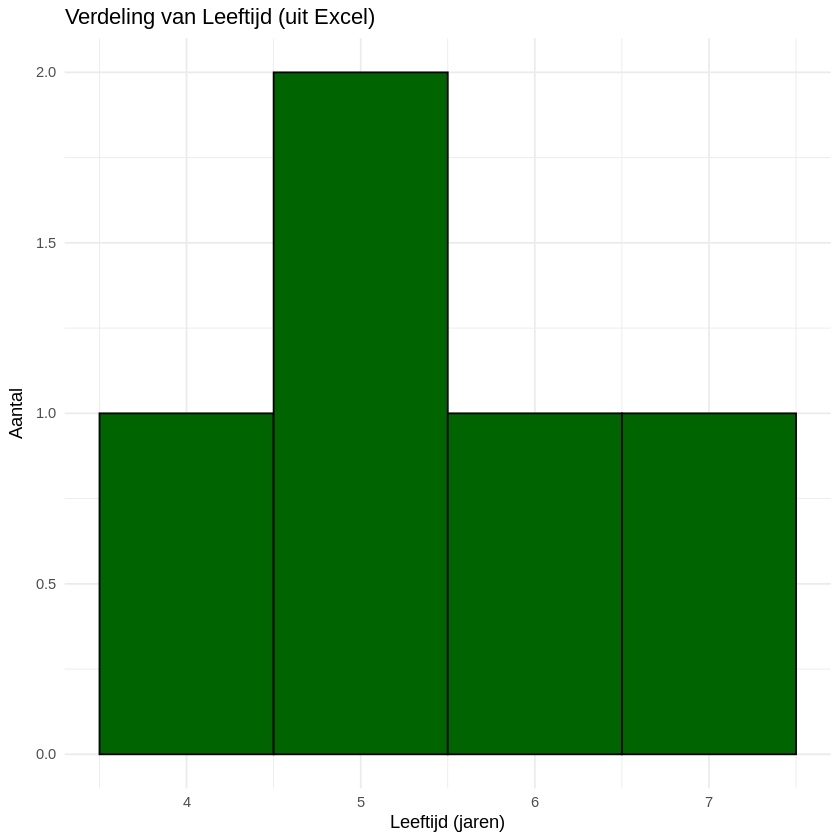

In [ ]:
hist_plot_excel <- ggplot(data = data.frame(leeftijd_excel = leeftijd_excel), aes(x = leeftijd_excel)) +
  geom_histogram(binwidth = 1, fill = "darkgreen", color = "black") +
  labs(title = "Verdeling van Leeftijd (uit Excel)",
       x = "Leeftijd (jaren)",
       y = "Aantal") +
  theme_minimal()

print(hist_plot_excel)

In [ ]:
install.packages("writexl")

Installing package into ‘/usr/local/lib/R/site-library’
(as ‘lib’ is unspecified)



In [ ]:
library(writexl)

In [ ]:
write_xlsx(data.frame(leeftijd_excel = leeftijd_excel), "leeftijd_excel.xlsx")